In [1]:
'''Design and implement deployment-ready machine learning pipelines that automate data preprocessing, model validation, and prediction generation, ensuring reproducibility and reliability for admission predictions.'''

'Design and implement deployment-ready machine learning pipelines that automate data preprocessing, model validation, and prediction generation, ensuring reproducibility and reliability for admission predictions.'

In [2]:
# import required libraries and load admission dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

df = pd.read_csv('Adm.csv')
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.96,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.80,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.67,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.78,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.63,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [3]:
# separate feature columns and target variable
x = df.drop(columns=['Serial No.', 'Application_DateTime', 'University_Name', 'Chance of Admit'])
y = df['Chance of Admit']
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("training samples:", len(x_train))
print("testing samples:", len(x_test))

training samples: 800
testing samples: 200


In [4]:
# construct deployment machine learning pipeline
num_cols = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
cat_cols = ['region']

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42))
])

pipeline.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [5]:
# perform cross validation to evaluate model reliability
cv_scores = cross_val_score(pipeline, x_train, y_train, cv=5, scoring='r2')
print("cv r2 scores:", cv_scores)
print("mean cv r2:", cv_scores.mean())

cv r2 scores: [0.91229748 0.9233282  0.89961267 0.91696794 0.91352886]
mean cv r2: 0.9131470301578739


In [6]:
# evaluate pipeline performance on testing dataset
y_pred = pipeline.predict(x_test)
print("mae:", mean_absolute_error(y_test, y_pred))
print("rmse:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("r2 score:", r2_score(y_test, y_pred))

mae: 0.023283000000000012
rmse: 0.030511624014463768
r2 score: 0.9090682555186558


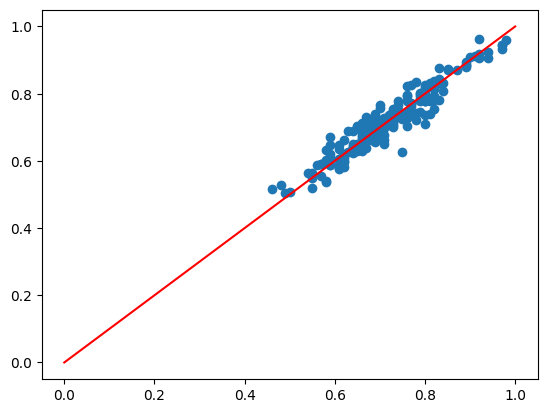

In [7]:
# plot actual versus predicted admission chance
plt.scatter(y_test, y_pred)
plt.plot([0, 1], [0, 1], color='red')
plt.show()

In [8]:
# save trained pipeline for deployment
joblib.dump(pipeline, 'admission_pipeline.pkl')
print("pipeline saved successfully")

pipeline saved successfully


In [9]:
# load pipeline and generate predictions for new applicants
loaded_pipeline = joblib.load('admission_pipeline.pkl')
sample_applicants = x_test.head(5)
sample_predictions = loaded_pipeline.predict(sample_applicants)
result = sample_applicants.copy()
result['predicted_chance'] = sample_predictions
print(result[['GRE Score', 'TOEFL Score', 'CGPA', 'region', 'predicted_chance']])

     GRE Score  TOEFL Score  CGPA     region  predicted_chance
521        337           99  9.32  Northeast            0.8129
737        297           95  8.79       West            0.6930
740        325          105  8.53      South            0.6989
660        339          114  9.55    Central            0.8940
411        313          114  8.06      North            0.6676
